# 2D Nonlinear Systems and Phase Plane

**References:** `Notes/lec11.pdf` (Lecture 11), `Notes/Problem Set II.pdf` (Q4), `Notes/tutorial_10_10_26.pdf`

## Concept & Formulas
System: $\dot{x} = f(x, y), \quad \dot{y} = g(x, y)$.

- **Step 1 — Fixed Points:** Find $(x^*, y^*)$ where both $f(x^*, y^*) = 0$ and $g(x^*, y^*) = 0$ (intersection of the two nullclines).
- **Step 2 — Jacobian Matrix:** Evaluate at each fixed point $(x^*, y^*)$:
  $$J = \begin{pmatrix} \frac{\partial f}{\partial x} & \frac{\partial f}{\partial y} \\ \frac{\partial g}{\partial x} & \frac{\partial g}{\partial y} \end{pmatrix}_{(x^*, y^*)}$$
- **Step 3 — Stability from Eigenvalues $\lambda_1, \lambda_2$:** Same rule as 2D linear systems:
  - Both $\text{Re}(\lambda) < 0 \implies$ **Stable** (node or inward spiral).
  - Both $\text{Re}(\lambda) > 0 \implies$ **Unstable** (node or outward spiral).
  - Opposite signs $\implies$ **Saddle** (unstable).
  - Pure imaginary $\implies$ **Center** in linear approximation (check nonlinear terms / numerical phase portrait).
- **Limitations:** Linearization fails when $\text{Re}(\lambda) = 0$ (borderline center), and Simple Euler drifts outward on closed orbits — use RK4 for long phase-plane trajectories.

*Professor code: None provided for 2D nonlinear phase portraits (uses Jacobian + RK4/Euler).*

Eigenvalues at (1, 1): [0.+1.j 0.-1.j]


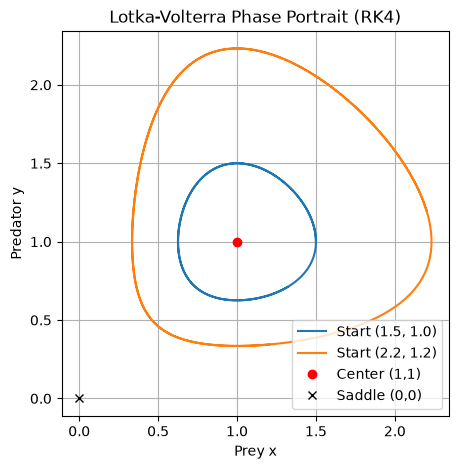

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Example: Lotka-Volterra Predator-Prey Model
# dx/dt = x - x*y,   dy/dt = -y + x*y
# Fixed points: (0, 0) [Saddle] and (1, 1) [Center]

def f_xy(x, y):
    return x - x * y, -y + x * y

# Check Jacobian at (1, 1): J = [[1 - y, -x], [y, -1 + x]] = [[0, -1], [1, 0]]
J_11 = np.array([[0, -1], [1, 0]])
print('Eigenvalues at (1, 1):', np.linalg.eigvals(J_11))

# Integrate two trajectories using RK4
dt = 0.02
t = np.arange(0, 12, dt)
n = len(t)

plt.figure(figsize=(5, 5))
for x0, y0 in [(1.5, 1.0), (2.2, 1.2)]:
    x = np.zeros(n); y = np.zeros(n)
    x[0], y[0] = x0, y0
    for i in range(n - 1):
        k1x, k1y = f_xy(x[i], y[i])
        k2x, k2y = f_xy(x[i] + 0.5*dt*k1x, y[i] + 0.5*dt*k1y)
        k3x, k3y = f_xy(x[i] + 0.5*dt*k2x, y[i] + 0.5*dt*k2y)
        k4x, k4y = f_xy(x[i] + dt*k3x, y[i] + dt*k3y)
        x[i + 1] = x[i] + dt * (k1x + 2*k2x + 2*k3x + k4x) / 6
        y[i + 1] = y[i] + dt * (k1y + 2*k2y + 2*k3y + k4y) / 6
    plt.plot(x, y, label=f'Start ({x0}, {y0})')

plt.plot(1, 1, 'ro', label='Center (1,1)')
plt.plot(0, 0, 'kx', label='Saddle (0,0)')
plt.xlabel('Prey x')
plt.ylabel('Predator y')
plt.title('Lotka-Volterra Phase Portrait (RK4)')
plt.legend()
plt.grid(True)
plt.show()